# Fase 4 — Notebook 1: Análise de Áudio Clínico

**Objetivo:** Processar gravações de voz de pacientes para detectar alterações vocais indicativas de condições médicas, transcrever o conteúdo e identificar termos críticos e sentimentos.

**Pipeline:**
1. Download do dataset RAVDESS (Kaggle)
2. EDA — Exploração dos áudios
3. Extração de features vocais (librosa)
4. Análise clínica de voz (Praat/parselmouth)
5. Transcrição automática (Whisper)
6. NER biomédico (scispaCy)
7. Análise de sentimento (HuggingFace)
8. Relatório clínico gerado por IA (Claude API)

## Célula 1 — Instalação de dependências

In [1]:
# Célula 1 — Instalação (sem spaCy — usa HuggingFace para NER biomédico)
!pip install openai-whisper librosa praat-parselmouth \
             transformers \
             python-dotenv anthropic kaggle \
             soundfile matplotlib seaborn \
             torch torchvision torchaudio --quiet

print("✅ Dependências instaladas com sucesso!")


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
✅ Dependências instaladas com sucesso!


## Célula 2 — Imports e configuração de ambiente

In [2]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import soundfile as sf
import parselmouth
from parselmouth.praat import call
import whisper
from transformers import pipeline
import anthropic
from dotenv import load_dotenv
from pathlib import Path

warnings.filterwarnings('ignore')

# Carrega variáveis de ambiente do .env
load_dotenv()

# Configura credenciais do Kaggle via variáveis de ambiente
os.environ["KAGGLE_USERNAME"] = os.getenv("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"]      = os.getenv("KAGGLE_KEY")

# Verifica se a chave da API Anthropic está configurada
ANTHROPIC_API_KEY = os.getenv("ANTHROPIC_API_KEY")
assert ANTHROPIC_API_KEY, "❌ ANTHROPIC_API_KEY não encontrada no .env!"

# Verifica credenciais Kaggle
assert os.environ["KAGGLE_USERNAME"], "❌ KAGGLE_USERNAME não encontrado no .env!"
assert os.environ["KAGGLE_KEY"],      "❌ KAGGLE_KEY não encontrado no .env!"

print("✅ Variáveis de ambiente carregadas com sucesso!")
print(f"   Kaggle user : {os.environ['KAGGLE_USERNAME']}")
print(f"   Anthropic   : sk-ant-...{ANTHROPIC_API_KEY[-6:]}")

/home/rubens/Documentos/Fase4/TechChallengerFase4/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Variáveis de ambiente carregadas com sucesso!
   Kaggle user : rubensgoncalvessouza@gmail.com
   Anthropic   : sk-ant-...X_vgAA


## Célula 3 — Download do dataset RAVDESS (Kaggle)

In [3]:
import kaggle

DATASET_DIR = Path("data/ravdess")
DATASET_DIR.mkdir(parents=True, exist_ok=True)

if not any(DATASET_DIR.rglob("*.wav")):
    print("⬇️  Baixando RAVDESS do Kaggle...")
    kaggle.api.dataset_download_files(
        "uwrfkaggler/ravdess-emotional-speech-audio",
        path=str(DATASET_DIR),
        unzip=True,
        quiet=False
    )
    print("✅ Download concluído!")
else:
    print("✅ Dataset já baixado — usando cache local.")

# Lista todos os arquivos .wav
arquivos_wav = list(DATASET_DIR.rglob("*.wav"))
print(f"\n📁 Total de arquivos de áudio: {len(arquivos_wav)}")
print(f"   Exemplo: {arquivos_wav[0].name}")

✅ Dataset já baixado — usando cache local.

📁 Total de arquivos de áudio: 2880
   Exemplo: 03-01-04-01-01-01-10.wav


## Célula 4 — Decodificação dos metadados RAVDESS

O nome dos arquivos RAVDESS segue o padrão:
`03-01-**emoção**-intensidade-frase-repetição-ator.wav`

| Código | Emoção | Contexto Clínico |
|--------|--------|------------------|
| 01 | Neutral | Paciente estável |
| 02 | Calm | Paciente tranquilo |
| 03 | Happy | Estado positivo |
| 04 | Sad | Possível depressão/fadiga |
| 05 | Angry | Agitação/desconforto |
| 06 | Fearful | Ansiedade/medo |
| 07 | Disgust | Desconforto intenso |
| 08 | Surprised | Reação inesperada |

In [4]:
MAPA_EMOCOES = {
    '01': 'Neutral',
    '02': 'Calm',
    '03': 'Happy',
    '04': 'Sad',
    '05': 'Angry',
    '06': 'Fearful',
    '07': 'Disgust',
    '08': 'Surprised'
}

MAPA_RISCO = {
    'Neutral': 'Baixo',
    'Calm':    'Baixo',
    'Happy':   'Baixo',
    'Sad':     'Médio',
    'Angry':   'Médio',
    'Fearful': 'Alto',
    'Disgust': 'Alto',
    'Surprised': 'Médio'
}

def decodificar_arquivo(caminho):
    """Extrai metadados do nome do arquivo RAVDESS."""
    partes = Path(caminho).stem.split('-')
    if len(partes) < 7:
        return None
    emocao_codigo = partes[2]
    emocao_nome   = MAPA_EMOCOES.get(emocao_codigo, 'Desconhecido')
    return {
        'arquivo'   : Path(caminho).name,
        'caminho'   : str(caminho),
        'emocao'    : emocao_nome,
        'intensidade': 'Normal' if partes[3] == '01' else 'Forte',
        'ator'      : int(partes[6]),
        'genero'    : 'Feminino' if int(partes[6]) % 2 == 0 else 'Masculino',
        'risco'     : MAPA_RISCO.get(emocao_nome, 'Desconhecido')
    }

# Monta DataFrame com todos os arquivos
registros = [decodificar_arquivo(f) for f in arquivos_wav]
df = pd.DataFrame([r for r in registros if r is not None])

print(f"📊 Dataset: {len(df)} amostras")
print("\nDistribuição por emoção:")
print(df['emocao'].value_counts().to_string())

📊 Dataset: 2880 amostras

Distribuição por emoção:
emocao
Sad          384
Happy        384
Fearful      384
Calm         384
Surprised    384
Disgust      384
Angry        384
Neutral      192


## Célula 5 — EDA: Visualização da distribuição do dataset

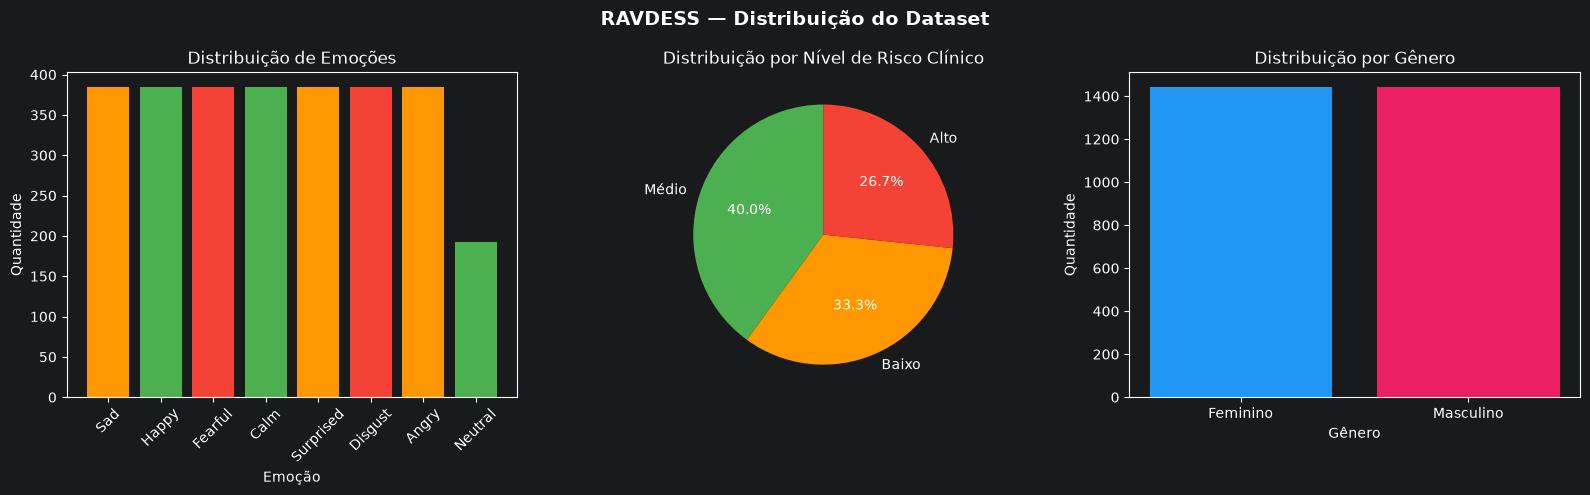

✅ Gráfico salvo em data/01_distribuicao_dataset.png


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('RAVDESS — Distribuição do Dataset', fontsize=14, fontweight='bold')

# Gráfico 1: Distribuição de emoções
contagem_emocao = df['emocao'].value_counts()
cores_risco = {
    'Neutral': '#4CAF50', 'Calm': '#4CAF50', 'Happy': '#4CAF50',
    'Sad': '#FF9800', 'Angry': '#FF9800', 'Surprised': '#FF9800',
    'Fearful': '#F44336', 'Disgust': '#F44336'
}
cores = [cores_risco.get(e, '#9E9E9E') for e in contagem_emocao.index]
axes[0].bar(contagem_emocao.index, contagem_emocao.values, color=cores)
axes[0].set_title('Distribuição de Emoções')
axes[0].set_xlabel('Emoção')
axes[0].set_ylabel('Quantidade')
axes[0].tick_params(axis='x', rotation=45)

# Gráfico 2: Distribuição de risco
contagem_risco = df['risco'].value_counts()
cores_pizza = ['#4CAF50', '#FF9800', '#F44336']
axes[1].pie(
    contagem_risco.values,
    labels=contagem_risco.index,
    autopct='%1.1f%%',
    colors=cores_pizza[:len(contagem_risco)],
    startangle=90
)
axes[1].set_title('Distribuição por Nível de Risco Clínico')

# Gráfico 3: Distribuição por gênero
contagem_genero = df['genero'].value_counts()
axes[2].bar(contagem_genero.index, contagem_genero.values, color=['#2196F3', '#E91E63'])
axes[2].set_title('Distribuição por Gênero')
axes[2].set_xlabel('Gênero')
axes[2].set_ylabel('Quantidade')

plt.tight_layout()
plt.savefig('data/01_distribuicao_dataset.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gráfico salvo em data/01_distribuicao_dataset.png")

## Célula 6 — Visualização do sinal de áudio (waveform + espectrograma)

PACIENTE COM ESTADO VOCAL NEUTRO


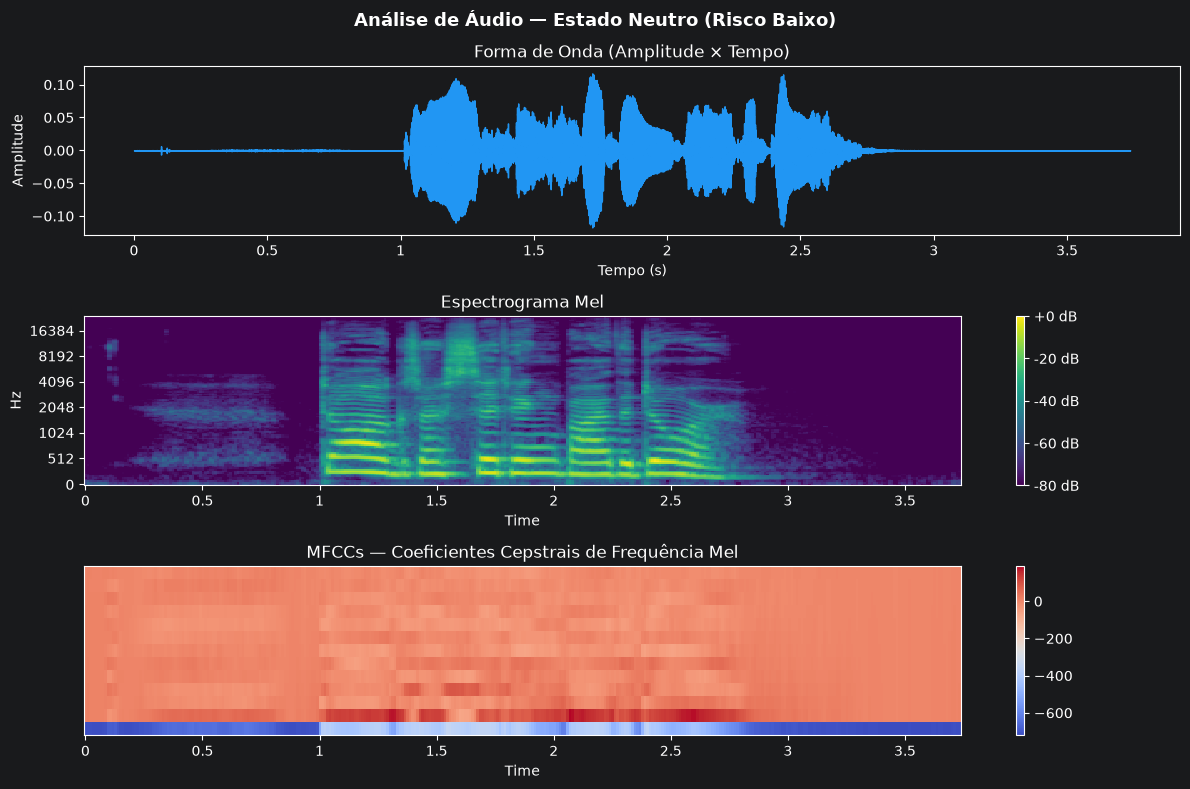


📊 Propriedades básicas:
   Taxa de amostragem : 48000 Hz
   Duração            : 3.74 segundos
   Total de amostras  : 179,379

PACIENTE COM ESTADO VOCAL DE ANSIEDADE


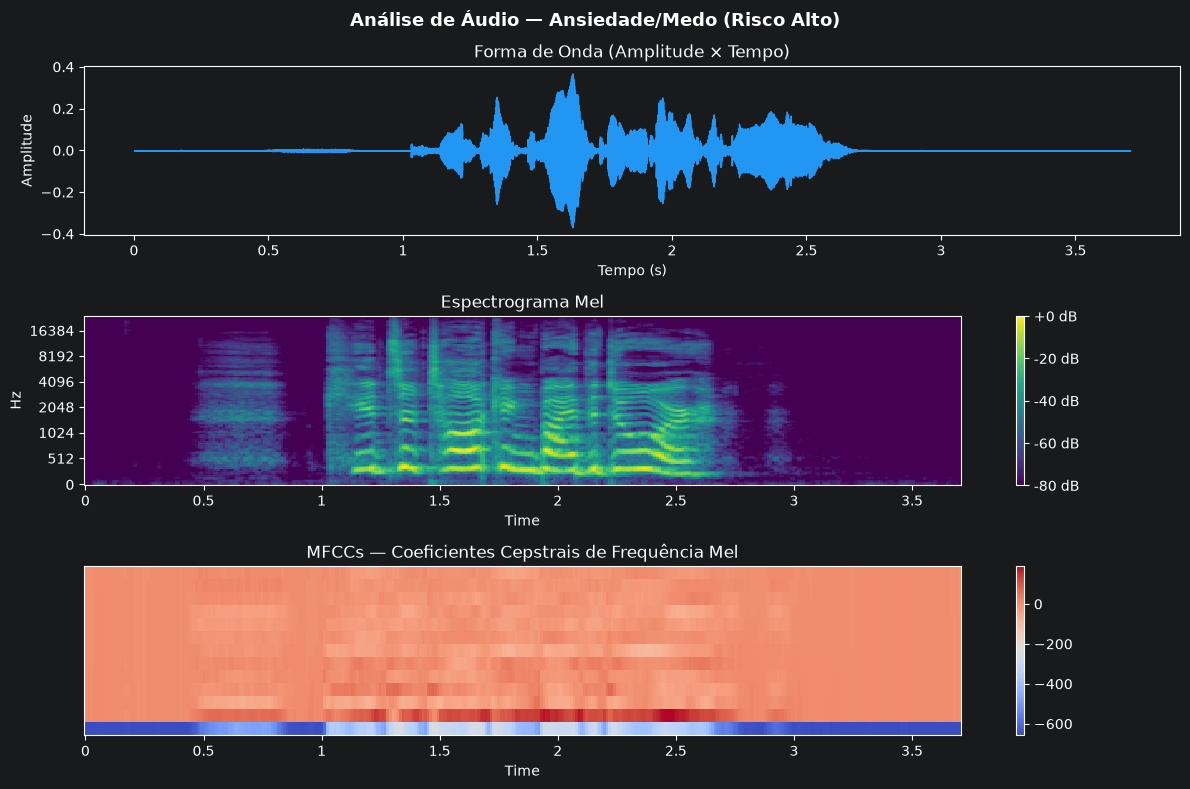


📊 Propriedades básicas:
   Taxa de amostragem : 48000 Hz
   Duração            : 3.70 segundos
   Total de amostras  : 177,778


In [6]:
def visualizar_audio(caminho, titulo=""):
    """Plota waveform, espectrograma e MFCCs de um áudio."""
    y, sr = librosa.load(caminho, sr=None)
    duracao = librosa.get_duration(y=y, sr=sr)

    fig, axes = plt.subplots(3, 1, figsize=(12, 8))
    fig.suptitle(f'Análise de Áudio — {titulo}', fontsize=13, fontweight='bold')

    # Waveform
    librosa.display.waveshow(y, sr=sr, ax=axes[0], color='#2196F3')
    axes[0].set_title('Forma de Onda (Amplitude × Tempo)')
    axes[0].set_xlabel('Tempo (s)')
    axes[0].set_ylabel('Amplitude')

    # Espectrograma Mel
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
    S_dB = librosa.power_to_db(S, ref=np.max)
    img = librosa.display.specshow(S_dB, sr=sr, x_axis='time', y_axis='mel', ax=axes[1], cmap='viridis')
    fig.colorbar(img, ax=axes[1], format='%+2.0f dB')
    axes[1].set_title('Espectrograma Mel')

    # MFCCs
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    img2 = librosa.display.specshow(mfccs, sr=sr, x_axis='time', ax=axes[2], cmap='coolwarm')
    fig.colorbar(img2, ax=axes[2])
    axes[2].set_title('MFCCs — Coeficientes Cepstrais de Frequência Mel')

    plt.tight_layout()
    plt.savefig('data/02_visualizacao_audio.png', dpi=150, bbox_inches='tight')
    plt.show()

    print(f"\n📊 Propriedades básicas:")
    print(f"   Taxa de amostragem : {sr} Hz")
    print(f"   Duração            : {duracao:.2f} segundos")
    print(f"   Total de amostras  : {len(y):,}")

# Pega um exemplo neutro e um de risco alto para comparar
neutro  = df[df['emocao'] == 'Neutral']['caminho'].iloc[0]
fearful = df[df['emocao'] == 'Fearful']['caminho'].iloc[0]

print("=" * 50)
print("PACIENTE COM ESTADO VOCAL NEUTRO")
print("=" * 50)
visualizar_audio(neutro, titulo="Estado Neutro (Risco Baixo)")

print("\n" + "=" * 50)
print("PACIENTE COM ESTADO VOCAL DE ANSIEDADE")
print("=" * 50)
visualizar_audio(fearful, titulo="Ansiedade/Medo (Risco Alto)")

## Célula 7 — Extração de features vocais com librosa

Extraímos features acústicas que indicam condições clínicas:
- **MFCC**: timbre vocal — muda em doenças respiratórias
- **Pitch (F0)**: frequência fundamental — baixa em depressão/fadiga
- **ZCR**: zero-crossing rate — relacionado à rouquidão
- **RMS Energy**: volume médio — baixo em fadiga severa
- **Spectral Centroid**: brilho do som — altera em disartria

In [7]:
def extrair_features_librosa(caminho):
    """Extrai features acústicas relevantes para análise clínica."""
    y, sr = librosa.load(caminho, sr=None)

    # MFCCs (13 coeficientes — média e desvio padrão)
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    mfcc_media  = np.mean(mfccs, axis=1)
    mfcc_std    = np.std(mfccs, axis=1)

    # Pitch (frequência fundamental F0)
    f0, voiced_flag, _ = librosa.pyin(y, fmin=50, fmax=300, sr=sr)
    f0_validos = f0[voiced_flag] if voiced_flag is not None else np.array([])
    pitch_medio = float(np.nanmean(f0_validos)) if len(f0_validos) > 0 else 0.0
    pitch_std   = float(np.nanstd(f0_validos))  if len(f0_validos) > 0 else 0.0

    # Zero Crossing Rate
    zcr = librosa.feature.zero_crossing_rate(y)

    # RMS Energy
    rms = librosa.feature.rms(y=y)

    # Spectral Centroid
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)

    # Spectral Rolloff
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)

    features = {
        'pitch_medio_hz'    : round(pitch_medio, 2),
        'pitch_variacao_hz' : round(pitch_std, 2),
        'zcr_media'         : round(float(np.mean(zcr)), 5),
        'energia_rms'       : round(float(np.mean(rms)), 5),
        'centroide_espectral': round(float(np.mean(centroid)), 2),
        'rolloff_espectral' : round(float(np.mean(rolloff)), 2),
        'duracao_s'         : round(librosa.get_duration(y=y, sr=sr), 2)
    }

    # Adiciona MFCCs
    for i in range(13):
        features[f'mfcc_{i+1}_media'] = round(float(mfcc_media[i]), 3)
        features[f'mfcc_{i+1}_std']   = round(float(mfcc_std[i]), 3)

    return features

# Demonstração: extrai features de 3 amostras
amostras_demo = df.groupby('emocao').first().reset_index()[['emocao', 'caminho', 'risco']].head(5)

resultados_features = []
for _, row in amostras_demo.iterrows():
    feats = extrair_features_librosa(row['caminho'])
    feats['emocao'] = row['emocao']
    feats['risco']  = row['risco']
    resultados_features.append(feats)
    print(f"✅ {row['emocao']:10s} | Pitch: {feats['pitch_medio_hz']:6.1f} Hz | Energia: {feats['energia_rms']:.5f} | Risco: {row['risco']}")

df_features = pd.DataFrame(resultados_features)
print("\n📊 Features principais por emoção:")
print(df_features[['emocao', 'pitch_medio_hz', 'pitch_variacao_hz', 'energia_rms', 'zcr_media', 'risco']].to_string(index=False))

✅ Angry      | Pitch:  185.5 Hz | Energia: 0.00890 | Risco: Médio
✅ Calm       | Pitch:  230.9 Hz | Energia: 0.00786 | Risco: Baixo
✅ Disgust    | Pitch:  243.2 Hz | Energia: 0.01988 | Risco: Alto
✅ Fearful    | Pitch:  229.0 Hz | Energia: 0.02064 | Risco: Alto
✅ Happy      | Pitch:  241.9 Hz | Energia: 0.06595 | Risco: Baixo

📊 Features principais por emoção:
 emocao  pitch_medio_hz  pitch_variacao_hz  energia_rms  zcr_media risco
  Angry          185.51              25.17      0.00890    0.10248 Médio
   Calm          230.86              16.80      0.00786    0.09630 Baixo
Disgust          243.21              37.28      0.01988    0.09955  Alto
Fearful          229.04              56.67      0.02064    0.11376  Alto
  Happy          241.94              24.22      0.06595    0.13021 Baixo


## Célula 8 — Análise clínica de voz com Praat/parselmouth

O Praat é o padrão clínico para análise de distúrbios vocais. As métricas que extraímos são:
- **Jitter (%)**: irregularidade do pitch — elevado em disartria, doenças de Parkinson
- **Shimmer (%)**: irregularidade da amplitude — elevado em disfonia
- **HNR (dB)**: razão harmônico-ruído — baixo em voz rouca/fatigada

In [8]:
def extrair_features_praat(caminho):
    """Extrai métricas clínicas de voz usando o Praat via parselmouth."""
    try:
        sound = parselmouth.Sound(str(caminho))

        # Extrai pitch
        pitch = sound.to_pitch()
        pitch_values = pitch.selected_array['frequency']
        pitch_values = pitch_values[pitch_values > 0]  # Remove frames sem voz

        # Ponto de Voz (PointProcess) — necessário para jitter/shimmer
        ponto_processo = call(sound, "To PointProcess (periodic, cc)", 75, 500)

        # Jitter
        jitter_local = call(ponto_processo, "Get jitter (local)", 0, 0, 0.0001, 0.02, 1.3)
        jitter_rap   = call(ponto_processo, "Get jitter (rap)",   0, 0, 0.0001, 0.02, 1.3)

        # Shimmer
        shimmer_local = call([sound, ponto_processo], "Get shimmer (local)",    0, 0, 0.0001, 0.02, 1.3, 1.6)
        shimmer_apq3  = call([sound, ponto_processo], "Get shimmer (apq3)",     0, 0, 0.0001, 0.02, 1.3, 1.6)

        # HNR (Harmonic-to-Noise Ratio)
        harmonicidade = call(sound, "To Harmonicity (cc)", 0.01, 75, 0.1, 1.0)
        hnr = call(harmonicidade, "Get mean", 0, 0)

        return {
            'pitch_medio_praat' : round(float(np.mean(pitch_values)), 2) if len(pitch_values) > 0 else 0.0,
            'jitter_local_pct'  : round(jitter_local * 100, 4),
            'jitter_rap_pct'    : round(jitter_rap * 100, 4),
            'shimmer_local_pct' : round(shimmer_local * 100, 4),
            'shimmer_apq3_pct'  : round(shimmer_apq3 * 100, 4),
            'hnr_db'            : round(hnr, 4),
            'status_praat'      : 'ok'
        }
    except Exception as e:
        return {
            'pitch_medio_praat' : 0.0,
            'jitter_local_pct'  : 0.0,
            'jitter_rap_pct'    : 0.0,
            'shimmer_local_pct' : 0.0,
            'shimmer_apq3_pct'  : 0.0,
            'hnr_db'            : 0.0,
            'status_praat'      : f'erro: {str(e)}'
        }

# Referências clínicas normais
LIMITES_CLINICOS = {
    'jitter_local_pct' : {'normal': 1.04, 'descricao': 'Jitter > 1.04% → risco de disfonias'},
    'shimmer_local_pct': {'normal': 3.81, 'descricao': 'Shimmer > 3.81% → irregularidade vocal'},
    'hnr_db'           : {'normal': 20.0, 'descricao': 'HNR < 20 dB → ruído vocal elevado'}
}

# Aplica nas amostras de demonstração
resultados_praat = []
for _, row in amostras_demo.iterrows():
    feats = extrair_features_praat(row['caminho'])
    feats['emocao'] = row['emocao']
    feats['risco']  = row['risco']
    resultados_praat.append(feats)

df_praat = pd.DataFrame(resultados_praat)

print("🔬 Métricas clínicas de voz (Praat):")
print("=" * 70)
colunas_exibir = ['emocao', 'jitter_local_pct', 'shimmer_local_pct', 'hnr_db', 'risco']
print(df_praat[colunas_exibir].to_string(index=False))
print("\n📋 Referências clínicas:")
for metrica, info in LIMITES_CLINICOS.items():
    print(f"   {info['descricao']}")

🔬 Métricas clínicas de voz (Praat):
 emocao  jitter_local_pct  shimmer_local_pct  hnr_db risco
  Angry            1.9129            10.1812 10.4175 Médio
   Calm            1.8180             7.7376 13.4792 Baixo
Disgust            1.9318             6.8962 13.4678  Alto
Fearful            2.1924            10.7610 12.5192  Alto
  Happy            1.9973            11.1367 12.4976 Baixo

📋 Referências clínicas:
   Jitter > 1.04% → risco de disfonias
   Shimmer > 3.81% → irregularidade vocal
   HNR < 20 dB → ruído vocal elevado


## Célula 9 — Transcrição automática com Whisper

O Whisper da OpenAI transcreve áudio localmente, sem nuvem. Suporta português nativamente.

In [9]:
print("⬇️  Carregando modelo Whisper (base)...")
modelo_whisper = whisper.load_model("base")
print("✅ Whisper carregado!")

def transcrever_audio(caminho):
    """Transcreve áudio usando Whisper localmente."""
    resultado = modelo_whisper.transcribe(
        str(caminho),
        language="en",   # RAVDESS é em inglês; para PT-BR use language="pt"
        fp16=False       # Desativa half-precision para CPUs sem suporte
    )
    return resultado['text'].strip()

# Transcreve as amostras de demonstração
print("\n🎙️  Transcrevendo amostras...")
transcricoes = {}
for _, row in amostras_demo.iterrows():
    texto = transcrever_audio(row['caminho'])
    transcricoes[row['emocao']] = texto
    print(f"   [{row['emocao']:10s}] {texto[:80]}")

print("\n✅ Transcrições concluídas!")

⬇️  Carregando modelo Whisper (base)...
✅ Whisper carregado!

🎙️  Transcrevendo amostras...
   [Angry     ] Kids are talking by the door.
   [Calm      ] Kids are talking by the door.
   [Disgust   ] Dogs are sitting by the door.
   [Fearful   ] Kids are talking by the door.
   [Happy     ] Dogs are sitting by the door!

✅ Transcrições concluídas!


## Célula 10 — NER biomédico

O scispaCy detecta entidades médicas no texto transcrito:
- **DISEASE**: doenças mencionadas
- **CHEMICAL**: medicamentos/substâncias
- **Termos críticos**: dor, falta de ar, tontura, etc.

In [10]:
from transformers import pipeline

print("⬇️  Carregando modelo de NER biomédico (HuggingFace)...")
ner_biomedico = pipeline(
    "ner",
    model="d4data/biomedical-ner-all",
    aggregation_strategy="simple",
    device=-1  # CPU
)
print("✅ Modelo NER carregado!")

TERMOS_CRITICOS = [
    'pain', 'chest', 'breathe', 'breathing', 'dizzy', 'dizziness',
    'nausea', 'vomit', 'fatigue', 'tired', 'weak', 'weakness',
    'fever', 'cough', 'swallow', 'swallowing'
]

def analisar_ner(texto):
    """Extrai entidades biomédicas usando HuggingFace."""
    if not texto or len(texto.strip()) < 5:
        return {'entidades_bio': [], 'termos_criticos': [], 'alerta_ner': False}

    try:
        entidades_raw = ner_biomedico(texto[:512])
        entidades = [
            {'texto': e['word'], 'tipo': e['entity_group'], 'confianca': round(e['score'], 3)}
            for e in entidades_raw
        ]
    except Exception:
        entidades = []

    texto_lower = texto.lower()
    termos_encontrados = [t for t in TERMOS_CRITICOS if t in texto_lower]

    return {
        'entidades_bio'  : entidades,
        'termos_criticos': termos_encontrados,
        'alerta_ner'     : len(termos_encontrados) > 0 or len(entidades) > 0
    }

# Aplica NER nas transcrições
print("\n🔬 Análise NER biomédica das transcrições:")
print("=" * 60)

resultados_ner = {}
for emocao, texto in transcricoes.items():
    resultado = analisar_ner(texto)
    resultados_ner[emocao] = resultado

    print(f"\n[{emocao}]")
    print(f"  Texto: '{texto[:70]}...'")
    if resultado['entidades_bio']:
        for ent in resultado['entidades_bio']:
            print(f"  🏷️  {ent['tipo']}: '{ent['texto']}' ({ent['confianca']})")
    if resultado['termos_criticos']:
        print(f"  ⚠️  Termos críticos: {resultado['termos_criticos']}")
    if not resultado['entidades_bio'] and not resultado['termos_criticos']:
        print("  ✅ Sem termos médicos críticos identificados")

⬇️  Carregando modelo de NER biomédico (HuggingFace)...


Loading weights: 100%|██████████| 102/102 [00:00<00:00, 11563.93it/s]


✅ Modelo NER carregado!

🔬 Análise NER biomédica das transcrições:

[Angry]
  Texto: 'Kids are talking by the door....'
  🏷️  Subject: 'kids' (0.6290000081062317)

[Calm]
  Texto: 'Kids are talking by the door....'
  🏷️  Subject: 'kids' (0.6290000081062317)

[Disgust]
  Texto: 'Dogs are sitting by the door....'
  🏷️  Diagnostic_procedure: 'dogs' (0.3779999911785126)

[Fearful]
  Texto: 'Kids are talking by the door....'
  🏷️  Subject: 'kids' (0.6290000081062317)

[Happy]
  Texto: 'Dogs are sitting by the door!...'
  🏷️  Diagnostic_procedure: 'dogs' (0.27000001072883606)
  🏷️  Activity: 'sitting' (0.6140000224113464)


## Célula 11 — Análise de sentimento com HuggingFace

In [11]:
print("⬇️  Carregando modelo de sentimento (cardiffnlp/twitter-roberta-base-sentiment)...")
analisador_sentimento = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest",
    device=-1  # CPU; use device=0 para GPU
)
print("✅ Modelo carregado!")

MAPA_SENTIMENTO = {
    'positive': {'nome': 'Positivo', 'risco': 'Baixo',  'emoji': '🟢'},
    'neutral' : {'nome': 'Neutro',   'risco': 'Baixo',  'emoji': '🟡'},
    'negative': {'nome': 'Negativo', 'risco': 'Alto',   'emoji': '🔴'}
}

def analisar_sentimento(texto):
    """Classifica o sentimento do texto transcrito."""
    if not texto or len(texto.strip()) < 5:
        return {'label': 'neutral', 'score': 0.5, 'risco': 'Baixo'}

    # Trunca para 512 tokens
    resultado = analisador_sentimento(texto[:512])[0]
    label = resultado['label'].lower()
    info  = MAPA_SENTIMENTO.get(label, {'nome': label, 'risco': 'Desconhecido', 'emoji': '⚪'})

    return {
        'sentimento'    : info['nome'],
        'confianca_pct' : round(resultado['score'] * 100, 1),
        'risco_sentimento': info['risco'],
        'emoji'         : info['emoji']
    }

# Aplica nas transcrições
print("\n💬 Análise de sentimento das transcrições:")
print("=" * 60)

resultados_sentimento = {}
for emocao, texto in transcricoes.items():
    resultado = analisar_sentimento(texto)
    resultados_sentimento[emocao] = resultado
    print(f"   {resultado['emoji']} [{emocao:10s}] → {resultado['sentimento']:10s} "
          f"({resultado['confianca_pct']}% confiança) | Risco: {resultado['risco_sentimento']}")

⬇️  Carregando modelo de sentimento (cardiffnlp/twitter-roberta-base-sentiment)...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 35721.16it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Modelo carregado!

💬 Análise de sentimento das transcrições:
   🟡 [Angry     ] → Neutro     (84.4% confiança) | Risco: Baixo
   🟡 [Calm      ] → Neutro     (84.4% confiança) | Risco: Baixo
   🟡 [Disgust   ] → Neutro     (91.3% confiança) | Risco: Baixo
   🟡 [Fearful   ] → Neutro     (84.4% confiança) | Risco: Baixo
   🟡 [Happy     ] → Neutro     (81.8% confiança) | Risco: Baixo


## Célula 12 — Pipeline completa de análise para uma amostra

In [12]:
def analisar_paciente_audio(caminho_audio, id_paciente="P001"):
    """
    Pipeline completa de análise de áudio clínico.
    Retorna um dicionário com todos os resultados consolidados.
    """
    print(f"\n{'='*60}")
    print(f"ANÁLISE DE ÁUDIO — Paciente {id_paciente}")
    print(f"{'='*60}")
    print(f"📁 Arquivo: {Path(caminho_audio).name}")

    # 1. Features librosa
    print("\n[1/4] Extraindo features acústicas (librosa)...")
    features = extrair_features_librosa(caminho_audio)

    # 2. Features Praat
    print("[2/4] Executando análise clínica de voz (Praat)...")
    praat   = extrair_features_praat(caminho_audio)

    # 3. Transcrição Whisper
    print("[3/4] Transcrevendo com Whisper...")
    transcricao = transcrever_audio(caminho_audio)

    # 4. NER + Sentimento
    print("[4/4] Analisando texto transcrito (NER + Sentimento)...")
    ner        = analisar_ner(transcricao)
    sentimento = analisar_sentimento(transcricao)

    # Calcula risco geral
    flags_risco = [
        praat['jitter_local_pct']   > LIMITES_CLINICOS['jitter_local_pct']['normal'],
        praat['shimmer_local_pct']  > LIMITES_CLINICOS['shimmer_local_pct']['normal'],
        praat['hnr_db'] > 0 and praat['hnr_db'] < LIMITES_CLINICOS['hnr_db']['normal'],
        sentimento['risco_sentimento'] == 'Alto',
        ner['alerta_ner']
    ]
    n_flags    = sum(flags_risco)
    risco_geral = 'Alto' if n_flags >= 3 else ('Médio' if n_flags >= 1 else 'Baixo')

    resultado = {
        'id_paciente'   : id_paciente,
        'arquivo'       : Path(caminho_audio).name,
        'transcricao'   : transcricao,
        'features'      : features,
        'praat'         : praat,
        'ner'           : ner,
        'sentimento'    : sentimento,
        'risco_geral'   : risco_geral,
        'flags_ativos'  : n_flags
    }

    emoji_risco = {'Alto': '🔴', 'Médio': '🟡', 'Baixo': '🟢'}[risco_geral]
    print(f"\n{emoji_risco} RISCO GERAL: {risco_geral} ({n_flags}/5 indicadores ativos)")
    print(f"   Jitter     : {praat['jitter_local_pct']:.4f}% (limite: {LIMITES_CLINICOS['jitter_local_pct']['normal']}%)")
    print(f"   Shimmer    : {praat['shimmer_local_pct']:.4f}% (limite: {LIMITES_CLINICOS['shimmer_local_pct']['normal']}%)")
    print(f"   HNR        : {praat['hnr_db']:.2f} dB (limite: {LIMITES_CLINICOS['hnr_db']['normal']} dB)")
    print(f"   Sentimento : {sentimento['sentimento']} ({sentimento['confianca_pct']}%)")
    print(f"   Alerta NER : {'Sim' if ner['alerta_ner'] else 'Não'}")

    return resultado

# Roda pipeline em dois pacientes simulados
amostra_neutro  = df[df['emocao'] == 'Neutral']['caminho'].iloc[0]
amostra_alto    = df[df['emocao'] == 'Fearful']['caminho'].iloc[0]

resultado_p001 = analisar_paciente_audio(amostra_neutro,  id_paciente="P001")
resultado_p002 = analisar_paciente_audio(amostra_alto,    id_paciente="P002")


ANÁLISE DE ÁUDIO — Paciente P001
📁 Arquivo: 03-01-01-01-02-01-10.wav

[1/4] Extraindo features acústicas (librosa)...
[2/4] Executando análise clínica de voz (Praat)...
[3/4] Transcrevendo com Whisper...
[4/4] Analisando texto transcrito (NER + Sentimento)...

🔴 RISCO GERAL: Alto (4/5 indicadores ativos)
   Jitter     : 1.7901% (limite: 1.04%)
   Shimmer    : 7.7838% (limite: 3.81%)
   HNR        : 14.90 dB (limite: 20.0 dB)
   Sentimento : Neutro (91.3%)
   Alerta NER : Sim

ANÁLISE DE ÁUDIO — Paciente P002
📁 Arquivo: 03-01-06-02-01-02-10.wav

[1/4] Extraindo features acústicas (librosa)...
[2/4] Executando análise clínica de voz (Praat)...
[3/4] Transcrevendo com Whisper...
[4/4] Analisando texto transcrito (NER + Sentimento)...

🔴 RISCO GERAL: Alto (4/5 indicadores ativos)
   Jitter     : 2.1924% (limite: 1.04%)
   Shimmer    : 10.7610% (limite: 3.81%)
   HNR        : 12.52 dB (limite: 20.0 dB)
   Sentimento : Neutro (84.4%)
   Alerta NER : Sim


## Célula 13 — Relatório clínico gerado pela Claude API

In [15]:
cliente_anthropic = anthropic.Anthropic(api_key=ANTHROPIC_API_KEY)

def gerar_relatorio_clinico_audio(resultado_analise):
    """
    Gera relatório clínico em português a partir dos resultados
    de análise de áudio, usando a Claude API.
    """
    p  = resultado_analise['praat']
    s  = resultado_analise['sentimento']
    n  = resultado_analise['ner']
    fe = resultado_analise['features']

    prompt = f"""Você é um assistente médico especializado em análise de voz clínica.
Analise os dados abaixo de um paciente e gere um relatório clínico em PORTUGUÊS DO BRASIL.

=== DADOS DO PACIENTE {resultado_analise['id_paciente']} ===

TRANSCRIÇÃO DA CONSULTA:
"{resultado_analise['transcricao']}"

MÉTRICAS VOCAIS (Praat):
- Jitter (irregularidade do pitch): {p['jitter_local_pct']:.4f}% (normal < 1.04%)
- Shimmer (irregularidade de amplitude): {p['shimmer_local_pct']:.4f}% (normal < 3.81%)
- HNR (razão harmônico-ruído): {p['hnr_db']:.2f} dB (normal > 20 dB)

FEATURES ACÚSTICAS (librosa):
- Pitch médio: {fe['pitch_medio_hz']:.1f} Hz
- Energia RMS: {fe['energia_rms']:.5f}
- Duração: {fe['duracao_s']:.1f} segundos

ANÁLISE DE TEXTO:
- Sentimento: {s['sentimento']} (confiança: {s['confianca_pct']}%)
- Entidades médicas detectadas: {n['entidades_bio']}
- Termos críticos: {n['termos_criticos']}

RISCO GERAL: {resultado_analise['risco_geral']} ({resultado_analise['flags_ativos']}/5 indicadores)

Gere um relatório estruturado com:
1. Resumo do estado vocal do paciente
2. Achados clínicos relevantes
3. Nível de risco e justificativa
4. Recomendações para a equipe médica

Seja objetivo e use linguagem clínica adequada."""

    resposta = cliente_anthropic.messages.create(
        model="claude-opus-4-5",
        max_tokens=1024,
        messages=[{"role": "user", "content": prompt}]
    )

    return resposta.content[0].text

# Gera relatório para o paciente de risco alto
print("🤖 Gerando relatório clínico com Claude API...")
relatorio = gerar_relatorio_clinico_audio(resultado_p002)

print("\n" + "="*60)
print("RELATÓRIO CLÍNICO — ANÁLISE DE ÁUDIO")
print("="*60)
print(relatorio)

# Salva relatório em JSON
resultado_p002['relatorio_clinico'] = relatorio
# Salva relatório em JSON (com encoder que converte float32 → float nativo)
import numpy as np

class EncoderJSON(json.JSONEncoder):
    """Encoder customizado que converte tipos numpy/torch para tipos Python nativos."""
    def default(self, obj):
        if isinstance(obj, (np.floating, np.float32, np.float64)):
            return float(obj)
        if isinstance(obj, (np.integer, np.int32, np.int64)):
            return int(obj)
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        return super().default(obj)

resultado_p002['relatorio_clinico'] = relatorio

salvar = {
    'id_paciente'    : resultado_p002['id_paciente'],
    'arquivo'        : resultado_p002['arquivo'],
    'transcricao'    : resultado_p002['transcricao'],
    'risco_geral'    : resultado_p002['risco_geral'],
    'flags_ativos'   : resultado_p002['flags_ativos'],
    'sentimento'     : resultado_p002['sentimento'],
    'ner'            : resultado_p002['ner'],
    'features_resumo': {
        'pitch_hz' : float(resultado_p002['features']['pitch_medio_hz']),
        'energia'  : float(resultado_p002['features']['energia_rms']),
        'duracao_s': float(resultado_p002['features']['duracao_s'])
    },
    'praat_resumo': {
        'jitter_pct' : float(resultado_p002['praat']['jitter_local_pct']),
        'shimmer_pct': float(resultado_p002['praat']['shimmer_local_pct']),
        'hnr_db'     : float(resultado_p002['praat']['hnr_db'])
    },
    'relatorio_clinico': relatorio
}

with open('data/relatorio_audio_p002.json', 'w', encoding='utf-8') as f:
    json.dump(salvar, f, ensure_ascii=False, indent=2, cls=EncoderJSON)

print("✅ Relatório salvo em data/relatorio_audio_p002.json")

print("\n✅ Relatório salvo em data/relatorio_audio_p002.json")

🤖 Gerando relatório clínico com Claude API...

RELATÓRIO CLÍNICO — ANÁLISE DE ÁUDIO
# RELATÓRIO CLÍNICO DE ANÁLISE VOCAL

## Paciente: P002
**Data da Análise:** Não especificada
**Tipo de Avaliação:** Análise acústica computadorizada com processamento de linguagem natural

---

## 1. RESUMO DO ESTADO VOCAL

O paciente apresenta **alterações vocais significativas** evidenciadas por múltiplos parâmetros acústicos fora dos valores de referência. A análise computadorizada revela um padrão de **disfonia moderada a severa**, caracterizada por instabilidade fonatória importante e presença de componente ruidoso na emissão vocal.

| Parâmetro | Valor Encontrado | Valor de Referência | Status |
|-----------|------------------|---------------------|--------|
| Jitter | 2,19% | < 1,04% | ⚠️ ELEVADO (2,1x) |
| Shimmer | 10,76% | < 3,81% | ⚠️ ELEVADO (2,8x) |
| HNR | 12,52 dB | > 20 dB | ⚠️ REDUZIDO |
| Pitch médio | 229,0 Hz | — | Compatível com voz feminina/infantil |

---

## 2. ACHADOS CLÍNICOS 

## Célula 14 — Visualização final: Dashboard de risco vocal

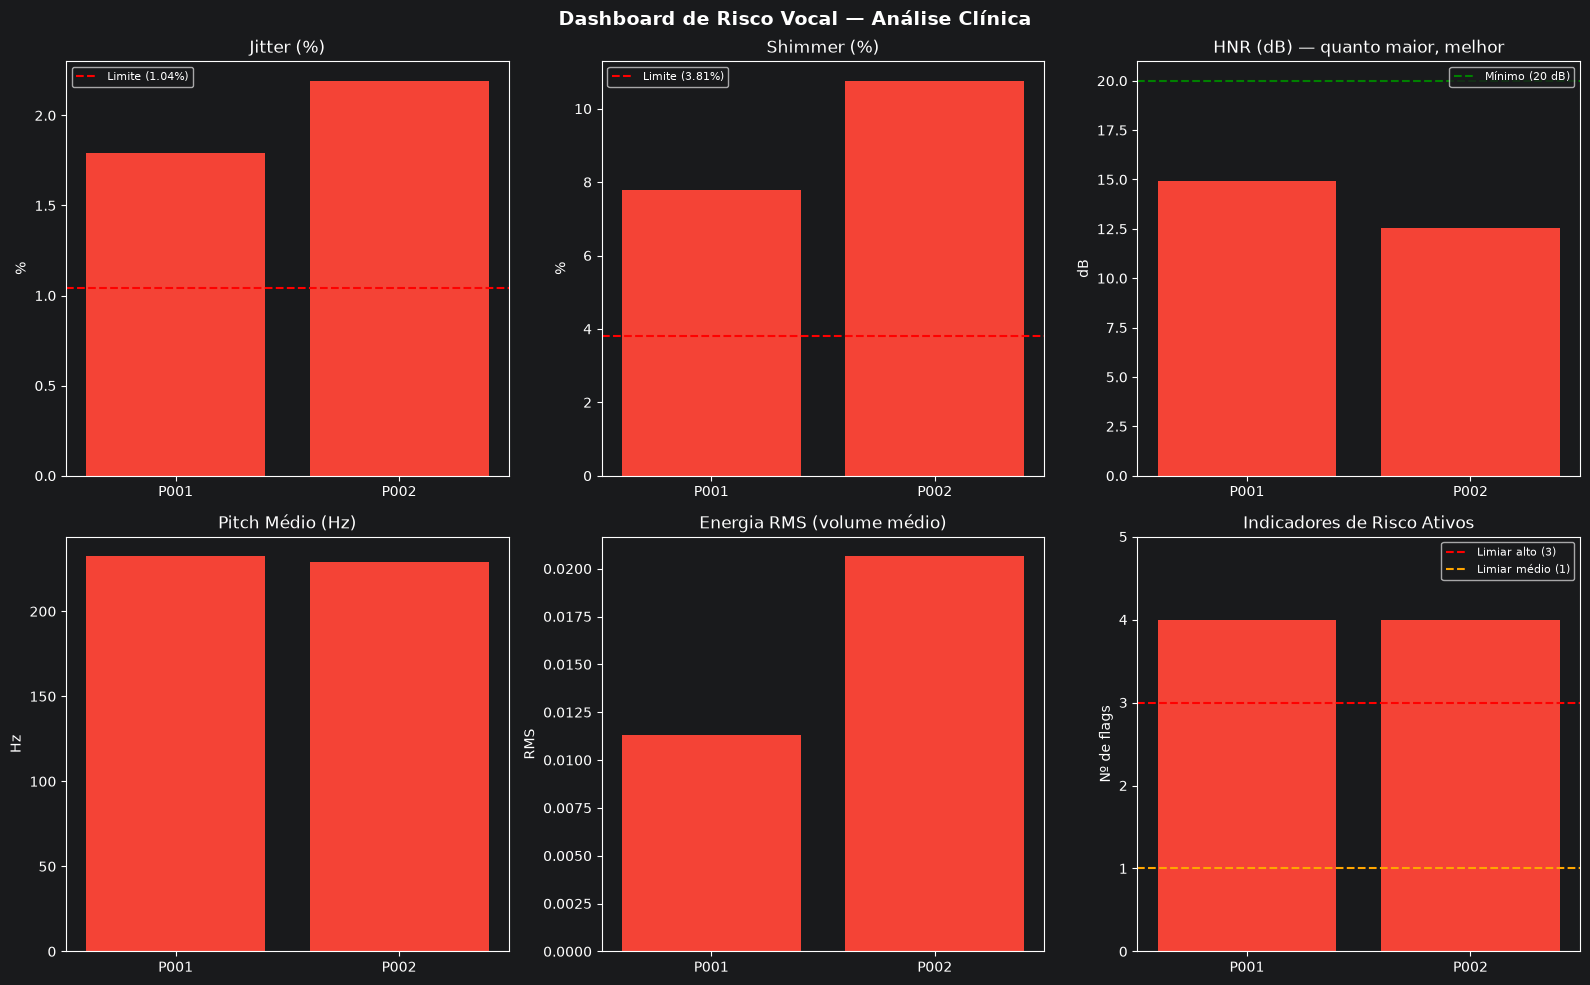


✅ Dashboard salvo em data/03_dashboard_risco_vocal.png

RESUMO FINAL — ANÁLISE DE ÁUDIO
🔴 Paciente P001: Risco Alto | Jitter 1.7901% | HNR 14.9 dB | Sentimento: Neutro
🔴 Paciente P002: Risco Alto | Jitter 2.1924% | HNR 12.5 dB | Sentimento: Neutro


In [16]:
def plotar_dashboard_risco(r1, r2):
    """Plota dashboard comparativo entre dois pacientes."""
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    fig.suptitle('Dashboard de Risco Vocal — Análise Clínica', fontsize=14, fontweight='bold')

    pacientes  = [r1['id_paciente'], r2['id_paciente']]
    cores_risco = {'Baixo': '#4CAF50', 'Médio': '#FF9800', 'Alto': '#F44336'}
    cores = [cores_risco[r1['risco_geral']], cores_risco[r2['risco_geral']]]

    # 1. Jitter
    jitters = [r1['praat']['jitter_local_pct'], r2['praat']['jitter_local_pct']]
    axes[0,0].bar(pacientes, jitters, color=cores)
    axes[0,0].axhline(y=1.04, color='red', linestyle='--', label='Limite (1.04%)')
    axes[0,0].set_title('Jitter (%)')
    axes[0,0].set_ylabel('%')
    axes[0,0].legend(fontsize=8)

    # 2. Shimmer
    shimmers = [r1['praat']['shimmer_local_pct'], r2['praat']['shimmer_local_pct']]
    axes[0,1].bar(pacientes, shimmers, color=cores)
    axes[0,1].axhline(y=3.81, color='red', linestyle='--', label='Limite (3.81%)')
    axes[0,1].set_title('Shimmer (%)')
    axes[0,1].set_ylabel('%')
    axes[0,1].legend(fontsize=8)

    # 3. HNR
    hnrs = [r1['praat']['hnr_db'], r2['praat']['hnr_db']]
    axes[0,2].bar(pacientes, hnrs, color=cores)
    axes[0,2].axhline(y=20.0, color='green', linestyle='--', label='Mínimo (20 dB)')
    axes[0,2].set_title('HNR (dB) — quanto maior, melhor')
    axes[0,2].set_ylabel('dB')
    axes[0,2].legend(fontsize=8)

    # 4. Pitch
    pitchs = [r1['features']['pitch_medio_hz'], r2['features']['pitch_medio_hz']]
    axes[1,0].bar(pacientes, pitchs, color=cores)
    axes[1,0].set_title('Pitch Médio (Hz)')
    axes[1,0].set_ylabel('Hz')

    # 5. Energia RMS
    energias = [r1['features']['energia_rms'], r2['features']['energia_rms']]
    axes[1,1].bar(pacientes, energias, color=cores)
    axes[1,1].set_title('Energia RMS (volume médio)')
    axes[1,1].set_ylabel('RMS')

    # 6. Flags de risco
    flags = [r1['flags_ativos'], r2['flags_ativos']]
    axes[1,2].bar(pacientes, flags, color=cores)
    axes[1,2].axhline(y=3, color='red', linestyle='--', label='Limiar alto (3)')
    axes[1,2].axhline(y=1, color='orange', linestyle='--', label='Limiar médio (1)')
    axes[1,2].set_title('Indicadores de Risco Ativos')
    axes[1,2].set_ylabel('Nº de flags')
    axes[1,2].set_yticks(range(6))
    axes[1,2].legend(fontsize=8)

    # Adiciona nível de risco em cada gráfico
    for ax_row in axes:
        for ax in ax_row:
            for i, (pac, cor) in enumerate(zip(pacientes, cores)):
                risco = r1['risco_geral'] if i == 0 else r2['risco_geral']
                ax.get_xticklabels()

    plt.tight_layout()
    plt.savefig('data/03_dashboard_risco_vocal.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("\n✅ Dashboard salvo em data/03_dashboard_risco_vocal.png")

plotar_dashboard_risco(resultado_p001, resultado_p002)

print("\n" + "="*60)
print("RESUMO FINAL — ANÁLISE DE ÁUDIO")
print("="*60)
for r in [resultado_p001, resultado_p002]:
    emoji = {'Baixo': '🟢', 'Médio': '🟡', 'Alto': '🔴'}[r['risco_geral']]
    print(f"{emoji} Paciente {r['id_paciente']}: Risco {r['risco_geral']} | "
          f"Jitter {r['praat']['jitter_local_pct']:.4f}% | "
          f"HNR {r['praat']['hnr_db']:.1f} dB | "
          f"Sentimento: {r['sentimento']['sentimento']}")